# What's Driving Negative Duolingo Reviews?
**INFO 4360 Course Project, Phase 2**

Teenna Pachika and Johanna Garcia

## Introduction
Duolingo has mostly positive reviews on Google Play, but about 8% are 1 or 2 stars. A star rating doesn't say *why* someone is unhappy, and the product team can't read thousands of reviews.

**Project question:** What are the most common complaints in negative Duolingo reviews, and do they change over time or after app updates?

**Data:** 50,000 Google Play reviews (US, English) collected with `google-play-scraper`, from July 29 to September 10, 2026. Usernames were removed for privacy.

**This notebook:** first we explore the data, then we apply text mining (keywords, complaint categories, sentiment, and topics), and finally we explain our plan for Phase 3.

### Setup
We load the data and the shared functions from `src/preprocessing.py`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.preprocessing import load_reviews, get_negative, clean_text

df = load_reviews()
neg = get_negative(df)

print(f"All reviews: {len(df):,}")
print(f"Negative reviews (1-2 stars): {len(neg):,} ({len(neg) / len(df):.1%})")

All reviews: 50,000
Negative reviews (1-2 stars): 4,147 (8.3%)


## Text Mining Basics

### **Sentiment Analysis**
We score every review with VADER, a lexicon-based sentiment model. Each review gets a score from -1 (very negative) to +1 (very positive). We use the raw text, not `clean_text`, because VADER uses capital letters, punctuation, and words like "not" to measure intensity.

In [2]:
from src.sentiment import add_sentiment, plot_sentiment_by_score, find_mismatches

# Score each review and add the result as a new column
df = add_sentiment(df)
neg = get_negative(df)   # update neg so it includes the sentiment column

# Average sentiment for each star rating
df.groupby("score")["sentiment"].mean().round(2)

score
1   -0.06
2    0.12
3    0.31
4    0.46
5    0.53
Name: sentiment, dtype: float64

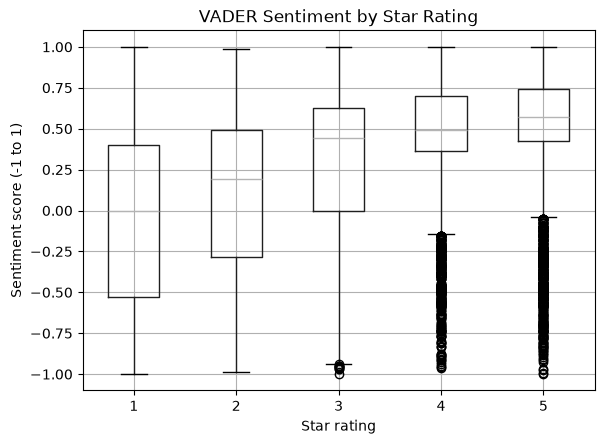

In [3]:
# Distribution of sentiment scores for each star rating
plot_sentiment_by_score(df)

**Sentiment** goes up with the star rating, from an average of -0.06 for 1-star reviews to 0.53 for 5-star reviews, so stars and text mostly agree. But 1-star reviews average close to 0, not strongly negative.

VADER struggles with complaints that use neutral or polite words (for example, "I lost my streak after the update"). Sentiment alone can't tell us *what* users are unhappy about, which is why we also need keywords, categories, and topics.

#### Mismatches: Negative Ratings with Positive Text
We look at 1-2 star reviews that VADER scored as clearly positive (above 0.5) and read a few of them.

In [4]:
mismatch = find_mismatches(neg)
print(f"{len(mismatch):,} of {len(neg):,} negative reviews ({len(mismatch) / len(neg):.1%}) have positive text")

pd.set_option("display.max_colwidth", None)
mismatch.sample(5, random_state=1)[["score", "sentiment", "content"]]

821 of 4,147 negative reviews (19.8%) have positive text


,score,sentiment,content
32065,1,0.7430,better not to download it has too many that my phone just lag it doesn't certificate after the course completion and one time I just jump in my lesson of English it just got another bug what happened next all my progress just reset and but also follow friends is also not working just bring the duo lingo last version
10045,1,0.7177,"Why don't you add Persian to this application? Many Iranian users use this program, yet you haven't included Persian — a beautiful and widely spoken language — while you have added Valyrian, which isn't even a real language! This is clearly a form of neglect and discrimination.💔👎"
14370,1,0.5719,I am happy
1468,2,0.8722,"It used to be a great app to learn a language. More than ten years after the creation of Duolingo, grammar is still neglected. Courses are repetitive, designed to make you feel good, while in reality making little progress, keeping you engaged to watch ads or pay for a version without ads. Its gamification promotes addiction, always raising the bar for monthly achievements beyond reasonable."
18891,1,0.8326,"Recently the need to get energy to continue doing questions has ruined the app for me. With the recent updates taking place I can tell they're trying to get people to pay for super Duolingo. I've had super Duolingo for a year and it just made the app bearable, to me, it felt like I was using the app like it was meant to be used. If you don't pay for super Duolingo you won't enjoy this app, it picks profit over quality."


About 1 in 5 negative reviews (19.8%) got a positive sentiment score. Reading five examples, most of them are clearly complaints:
- **Bugs:** lag, lost progress, and features that stop working.
- **Energy and paywall:** the new energy system pushes users to pay for Super Duolingo.
- **Ads and course quality:** "it used to be a great app," but now it is repetitive and full of ads.
- **Missing languages:** a user asks for Persian.

VADER scored them as positive because they use words like "great," "beautiful," "enjoy," and "friends," even though the user is complaining. Only one review ("I am happy") seems truly positive, so that user probably picked the wrong star rating.

VADER reads words one by one, so it misses context like "it used to be great" or "you won't enjoy this unless you pay." For our project, star ratings are a better filter for unhappy users than sentiment scores. To understand *why* users are unhappy, we need complaint categories and topics, and possibly Claude, which can read the full context of a review. Several of these examples already match our expected categories (bugs, energy, paywall, ads).

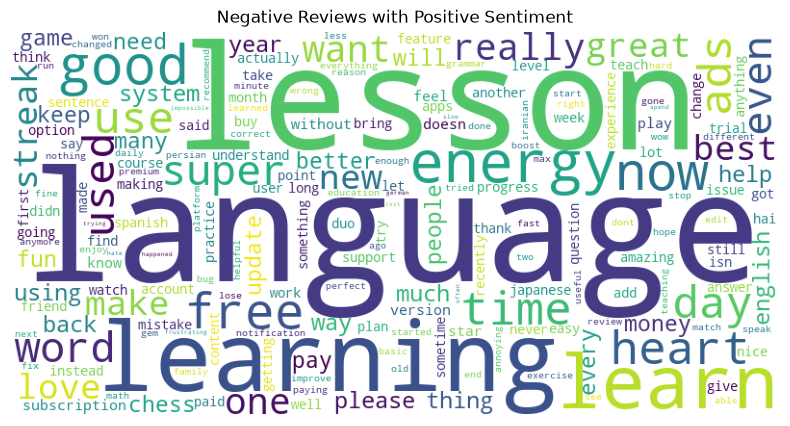

In [5]:
from src.sentiment import plot_wordcloud

plot_wordcloud(mismatch["content"], title="Negative Reviews with Positive Sentiment")

The biggest words ("language," "lesson," "learning") are general learning words that appear in almost any review. The more useful words are "energy," "heart," "ads," "super," "free," "pay," "streak," "update," and "subscription." Words like "used" and "now" also suggest users comparing the app to how it was before.

Even when the text sounds positive, these users are mostly complaining about the energy/hearts system, ads, paying for Super, and losing streaks after updates. This matches our complaint categories and shows that sentiment scores alone would miss these complaints.

### **Topic Modeling**
We use NMF (Non-negative Matrix Factorization) on TF-IDF features to find the main themes in negative reviews, without telling the model what to look for. We only use reviews with at least 5 words, because very short reviews like "bad app" don't have enough words to form a topic. Then we compare the topics with our expected complaint categories.

We skip NER (Named Entity Recognition) because names of people and places don't help explain why users are unhappy.

In [6]:
from src.topics import build_tfidf, show_topics, assign_topics

# Words that appear in almost every review and hide the real complaints
extra_stopwords = [ "duolingo", "app", "duo", "language", "languages", 
    "learn", "learning", "english", "lesson", "lessons",
    "good", "bad", "best", "worst", "great", "love", "hate", "annoying", "irritating",
    "sucks", "ugly", "disgusting", "better", "worse",
    "like", "really", "just", "don", "doesn", "did", "didn", "ve", "got", "want", "know",
    "make", "makes", "use", "using", "say", "need", "think", "feel", "feels", "way", "thing",
    "time", "day", "people", "new", "used", "soo", "hai", "fun", "waste", "help", "experience",
]

long_neg = neg[neg["n_words"] >= 5].copy()
tfidf, T = build_tfidf(long_neg["content"], extra_stopwords=extra_stopwords)

print(f"Negative reviews with 5+ words: {len(long_neg):,}")
print(f"Words and phrases used: {T.shape[1]:,}")

Negative reviews with 5+ words: 3,267
Words and phrases used: 1,771


#### Choosing the Number of Topics
In our first try, generic words like "language," "learn," "english," and "good" appeared in almost every topic, so the topics were hard to tell apart. We added these words to the stopword list so the model focuses on the actual complaints. Then we tried 6, 8, and 10 topics.

In [7]:
for k in [6, 8, 10]:
    print(f"\n===== {k} topics =====")
    nmf, topics = show_topics(tfidf, T, k)
    print(topics.to_string())


===== 6 topics =====
Topic 0                               energy, hearts, streak, update, icon, pay, change, gems, bring, hearts energy
Topic 1    iranian, test, students, decision, users, iranian users, taking, disappointed, nationality, users taking
Topic 2                                   ads, ad, close, watch, ads ads, super, stop, watching, watch ads, youtube
Topic 3                                    chess, play, oscar, play chess, game, course, elo, match, option, pieces
Topic 4                                   ai, slop, ai slop, words, garbage, mistakes, wrong, things, uses, uses ai
Topic 5                             free, subscription, money, trial, free trial, super, year, cancel, pay, version

===== 8 topics =====
Topic 0                      energy, hearts, pay, bring, hearts energy, heart, bring hearts, gems, mistakes, update
Topic 1    iranian, test, students, decision, users, iranian users, taking, disappointed, nationality, users taking
Topic 2                     

c:\Users\JGARC\venvs\info4360\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


With 6 topics, energy, streaks, and the app icon are mixed in one group. With 8, energy separates, but streaks are still mixed with lesson content. With 10, every topic is about one clear theme, so we keep **10 topics**.

#### Topic Summary

| Topic | Name | Top words | Reviews |
|---|---|---|---|
| 8 | Course content and updates | words, update, teach, wrong | 1,081 |
| 5 | Subscriptions and billing | free trial, subscription, cancel, charged | 414 |
| 0 | Energy and hearts | energy, hearts, pay, gems | 326 |
| 6 | Lost streaks | streak, lost, streak freezes, account | 258 |
| 7 | App icon changes | icon, changing, owl, faces | 246 |
| 3 | Chess course | chess, play, elo, match | 221 |
| 4 | AI-generated content | ai, slop, garbage, mistakes | 212 |
| 2 | Ads | ads, close, watch ads | 207 |
| 9 | Language requests | add, persian, urdu, farsi | 185 |
| 1 | Iranian users and the English Test | iranian, test, students, nationality | 117 |

Topic modeling found 10 clear themes in negative reviews. The largest one, course content and updates (1,081 reviews), is broad and covers different problems with lessons, like wrong answers and changes after updates. After that, the biggest complaints are about subscriptions and billing (414), energy and hearts (326), and lost streaks (258). Some smaller topics are very specific, like the chess course, requests to add languages such as Persian and Urdu, and Iranian users who can't take the English Test. "Bugs" doesn't appear as its own topic, probably because users describe bugs in many different ways.

Most of the complaints are about how Duolingo makes money and keeps users coming back (subscriptions, energy, ads, and streaks), not about the language content itself. For Duolingo's product team, the subscription and energy systems are the first places to look.